# Comparación temporal de variables e indicadores de faltantes

Este notebook compara el conjunto de 26 variables usado actualmente, el conjunto exploratorio de 59 variables y una selección dinámica por corte. También comprueba si los indicadores binarios de faltantes ayudan a HistGradientBoosting.

Se usan los hiperparámetros seleccionados previamente. No se vuelven a optimizar y no se evalúan los años 2017 en adelante.

## 1. Diseño del experimento

Se evalúan seis variantes en los mismos cortes expansivos: entrenamiento hasta 2012 y validación 2013; hasta 2013 y validación 2014; hasta 2014 y validación 2015; hasta 2015 y validación 2016.

- **A/B (26 variables):** lista fijada con la cobertura faltante del primer entrenamiento (hasta 2012). B añade indicadores para numéricas con faltantes en el entrenamiento de cada corte.
- **C/D (59 variables, exploratorias):** lista fijada por tener menos de 10% de faltantes hasta 2016. D añade los mismos indicadores. Como la selección observó los años de validación, C/D sirven como comparación exploratoria, no como validación temporal estrictamente independiente.
- **E/F (selección temporal):** en cada corte, las variables se seleccionan desde las candidatas si tienen menos de 10% de faltantes en ese corte de entrenamiento. F añade indicadores. La cantidad y nombres de variables pueden cambiar por corte.

En todos los casos la mediana numérica, categorías del One-Hot, escalado e indicadores se determinan usando solo el entrenamiento del corte. Las categóricas se completan con «Sin información». Los indicadores se crean antes de imputar. El umbral es estricto: se conserva una variable solo si el porcentaje es **menor a 10%**. La selección temporal no usa etiquetas de validación para elegir variables.

In [1]:
from pathlib import Path
import sys, time, gc, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import localizar_datos, MAPA_OBJETIVO, SEMILLA
from src.modelado import TIPOS_AUDITADOS
from src import features as ft

SEMILLA = 42
ANIOS_VALIDACION = [2013, 2014, 2015, 2016]
UMBRAL_FALTANTES = 10

ruta_datos = localizar_datos()
columnas_fuente = pd.read_csv(ruta_datos, nrows=0).columns.tolist()
candidatas = ft.seleccionar_predictoras(
    pd.DataFrame(columns=columnas_fuente), [], incluir_precio_lc=False
)
columnas_lectura = candidatas + ["loan_status", "issue_d"]
dtypes = {
    c: ("string" if TIPOS_AUDITADOS[c] in ["category", "string"] else TIPOS_AUDITADOS[c])
    for c in columnas_lectura
}
print(f"Candidatas previas al filtro: {len(candidatas)}")
print("Leyendo por bloques y reteniendo solo préstamos elegibles hasta 2016...")

partes = []
filas_leidas = 0
inicio_carga = time.perf_counter()
with pd.read_csv(ruta_datos, usecols=columnas_lectura, dtype=dtypes,
                 chunksize=100_000, skipinitialspace=True, low_memory=False) as lector:
    for numero, bloque in enumerate(lector, start=1):
        filas_leidas += len(bloque)
        fecha = pd.to_datetime(bloque["issue_d"], format="%b-%Y", errors="coerce")
        # Primero limitamos por fecha. Las etiquetas y variables de 2017+ no entran al análisis.
        conservar_fecha = fecha.notna() & (fecha.dt.year <= 2016)
        bloque = bloque.loc[conservar_fecha].copy()
        bloque["issue_d"] = fecha.loc[conservar_fecha]
        elegibles = bloque["loan_status"].isin(MAPA_OBJETIVO)
        bloque = bloque.loc[elegibles].copy()
        if bloque.empty:
            continue
        for col in ["earliest_cr_line", "sec_app_earliest_cr_line"]:
            if col in bloque:
                original = bloque[col].notna()
                convertida = pd.to_datetime(bloque[col], format="%b-%Y", errors="coerce")
                if (original & convertida.isna()).any():
                    raise ValueError(f"Fecha no reconocida en {col}")
                bloque[col] = convertida
        if "term" in bloque:
            bloque["term"] = pd.to_numeric(
                bloque["term"].astype("string").str.strip().str.replace(" months", "", regex=False),
                errors="raise"
            ).astype("float64")
        bloque["anio"] = bloque["issue_d"].dt.year.astype("int16")
        bloque["default"] = bloque["loan_status"].map(MAPA_OBJETIVO).astype("int8")
        bloque["fecha_prestamo"] = bloque["issue_d"]
        partes.append(bloque)
        if numero % 10 == 0:
            print(f"  Bloques leídos: {numero}; filas fuente recorridas: {filas_leidas:,}", flush=True)

datos = pd.concat(partes, ignore_index=True)
del partes
print(f"Datos de análisis: {len(datos):,} préstamos elegibles hasta 2016; carga {time.perf_counter()-inicio_carga:.1f} s")
print("Años incluidos:", int(datos["anio"].min()), "a", int(datos["anio"].max()))
assert datos["anio"].max() <= 2016

# Lista fija A/B: faltantes medidos solo en el primer entrenamiento, hasta 2012.
mascara_2012 = datos["anio"] <= 2012
faltantes_hasta_2012 = datos.loc[mascara_2012, candidatas].isna().mean() * 100
variables_26 = faltantes_hasta_2012[faltantes_hasta_2012 < UMBRAL_FALTANTES].index.tolist()

# Lista exploratoria C/D: su selección observa el patrón de faltantes hasta 2016.
faltantes_hasta_2016 = datos[candidatas].isna().mean() * 100
variables_59 = faltantes_hasta_2016[faltantes_hasta_2016 < UMBRAL_FALTANTES].index.tolist()

print(f"A/B: {len(variables_26)} variables seleccionadas hasta 2012")
print(f"C/D: {len(variables_59)} variables seleccionadas hasta 2016 (exploratorio)")
print(f"Candidatas para E/F: {len(candidatas)}")
if len(variables_26) != 26 or len(variables_59) != 59:
    raise ValueError(f"Se esperaba 26 y 59 variables; se obtuvieron {len(variables_26)} y {len(variables_59)}")

tabla_resumen_seleccion = pd.DataFrame({
    "conjunto": ["Candidatas", "26 fijas (hasta 2012)", "59 fijas (hasta 2016, exploratorio)"],
    "cantidad": [len(candidatas), len(variables_26), len(variables_59)],
})
display(tabla_resumen_seleccion)

# Fechas del historial a antigüedad, igual que en el pipeline anterior.
def derivar_antiguedad(X, fecha_otorgamiento):
    X = X.copy()
    if "earliest_cr_line" in X:
        fecha_inicio = X["earliest_cr_line"]
        X["meses_desde_earliest_cr_line"] = (
            (fecha_otorgamiento.dt.year - fecha_inicio.dt.year) * 12
            + (fecha_otorgamiento.dt.month - fecha_inicio.dt.month)
        ).astype("float64")
        X = X.drop(columns="earliest_cr_line")
    if "sec_app_earliest_cr_line" in X:
        fecha_inicio = X["sec_app_earliest_cr_line"]
        X["meses_desde_sec_app_earliest_cr_line"] = (
            (fecha_otorgamiento.dt.year - fecha_inicio.dt.year) * 12
            + (fecha_otorgamiento.dt.month - fecha_inicio.dt.month)
        ).astype("float64")
        X = X.drop(columns="sec_app_earliest_cr_line")
    for col in X.columns:
        if pd.api.types.is_numeric_dtype(X[col]):
            X[col] = pd.to_numeric(X[col], errors="coerce").astype("float64")
            X[col] = X[col].replace([np.inf, -np.inf], np.nan)
        else:
            X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
    return X



Candidatas previas al filtro: 95
Leyendo por bloques y reteniendo solo préstamos elegibles hasta 2016...


  Bloques leídos: 10; filas fuente recorridas: 1,000,000


  Bloques leídos: 20; filas fuente recorridas: 2,000,000


Datos de análisis: 1,119,699 préstamos elegibles hasta 2016; carga 90.8 s
Años incluidos: 2007 a 2016


A/B: 26 variables seleccionadas hasta 2012
C/D: 59 variables seleccionadas hasta 2016 (exploratorio)
Candidatas para E/F: 95


,conjunto,cantidad
0,Candidatas,95
1,26 fijas (hasta 2012),26
2,"59 fijas (hasta 2016, exploratorio)",59


## 2. Preprocesamiento por corte

La siguiente función crea los indicadores a partir de los faltantes originales del entrenamiento, mantiene esas mismas columnas y orden en validación, y luego imputa. `SimpleImputer` y `OneHotEncoder` se ajustan únicamente con el entrenamiento. Las categorías nuevas que aparezcan en validación se ignoran en la codificación, sin detener el experimento.

In [2]:
HIPERPARAMETROS = {
    "learning_rate": 0.08118441500491742,
    "max_iter": 182,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 46,
    "l2_regularization": 0.32877474139911184,
    "early_stopping": False,
    "random_state": SEMILLA,
}

def evaluar_corte(anio_validacion, variables, usar_indicadores, nombre_experimento):
    anio_final_train = anio_validacion - 1
    mascara_train = datos["anio"] <= anio_final_train
    mascara_valid = datos["anio"] == anio_validacion
    fecha_train = datos.loc[mascara_train, "fecha_prestamo"]
    fecha_valid = datos.loc[mascara_valid, "fecha_prestamo"]
    X_train = derivar_antiguedad(datos.loc[mascara_train, variables], fecha_train)
    X_valid = derivar_antiguedad(datos.loc[mascara_valid, variables], fecha_valid)
    y_train = datos.loc[mascara_train, "default"].to_numpy(dtype="int8")
    y_valid = datos.loc[mascara_valid, "default"].to_numpy(dtype="int8")

    numericas = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
    categoricas = [c for c in X_train.columns if c not in numericas]
    nombres_indicadores = []
    if usar_indicadores:
        # Construir 0/1 antes de imputar, usando faltantes originales.
        for col in numericas:
            if X_train[col].isna().any():
                nombre = f"{col}__faltante"
                if nombre in X_train.columns:
                    raise ValueError(f"Colisión de nombre para indicador: {nombre}")
                X_train[nombre] = X_train[col].isna().astype("int8")
                X_valid[nombre] = X_valid[col].isna().astype("int8")
                nombres_indicadores.append(nombre)

    transformadores = []
    if numericas:
        transformadores.append((
            "numericas",
            Pipeline([
                ("imputar", SimpleImputer(strategy="median")),
                ("escalar", StandardScaler()),
            ]),
            numericas,
        ))
    if categoricas:
        transformadores.append((
            "categoricas",
            Pipeline([
                ("imputar", SimpleImputer(strategy="constant", fill_value="Sin información")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore", drop="first", sparse_output=False,
                    dtype=np.float32,
                )),
            ]),
            categoricas,
        ))
    if nombres_indicadores:
        transformadores.append(("indicadores", "passthrough", nombres_indicadores))
    preprocesador = ColumnTransformer(
        transformadores, remainder="drop", sparse_threshold=0.0
    )
    modelo = HistGradientBoostingClassifier(**HIPERPARAMETROS)
    pipeline = Pipeline([("preprocesar", preprocesador), ("modelo", modelo)])
    inicio = time.perf_counter()
    pipeline.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    puntuacion = pipeline.predict_proba(X_valid)[:, 1]

    roc = roc_auc_score(y_valid, puntuacion)
    ap = average_precision_score(y_valid, puntuacion)
    faltantes_train = datos.loc[mascara_train, variables].isna().mean() * 100
    detalle_faltantes = pd.DataFrame({
        "experimento": nombre_experimento,
        "anio_validacion": anio_validacion,
        "variable": variables,
        "faltante_pct_entrenamiento": [float(faltantes_train.get(v, np.nan)) for v in variables],
        "indicador_creado": [bool(f"{v}__faltante" in nombres_indicadores) for v in variables],
    })
    fila = {
        "experimento": nombre_experimento,
        "anio_final_entrenamiento": anio_final_train,
        "anio_validacion": anio_validacion,
        "filas_entrenamiento": len(y_train),
        "filas_validacion": len(y_valid),
        "variables_originales": len(variables),
        "indicadores_faltantes": len(nombres_indicadores),
        "variables_numericas": len(numericas),
        "variables_categoricas": len(categoricas),
        "faltante_promedio_pct_entrenamiento": float(faltantes_train.mean()),
        "faltante_maximo_pct_entrenamiento": float(faltantes_train.max()),
        "tasa_incumplimiento_validacion": float(y_valid.mean()),
        "ROC_AUC": float(roc),
        "PR_AUC": float(ap),
        "segundos_ajuste": float(segundos),
    }
    del pipeline, puntuacion, X_train, X_valid
    gc.collect()
    return fila, detalle_faltantes

experimentos = {
    "A_26_sin_indicadores": ("26 fijas", variables_26, False, "rigurosa"),
    "B_26_con_indicadores": ("26 fijas", variables_26, True, "rigurosa"),
    "C_59_sin_indicadores": ("59 fijas", variables_59, False, "exploratoria"),
    "D_59_con_indicadores": ("59 fijas", variables_59, True, "exploratoria"),
}
filas_resultados = []
filas_faltantes = []


In [3]:
# Selección E/F calculada únicamente con el entrenamiento de este corte.
mascara_train = datos["anio"] <= 2012
faltantes_train_corte = datos.loc[mascara_train, candidatas].isna().mean() * 100
variables_corte = faltantes_train_corte[faltantes_train_corte < UMBRAL_FALTANTES].index.tolist()
if not variables_corte:
    raise ValueError("El corte no dejó variables predictoras.")

experimentos_corte = {
    "A_26_sin_indicadores": variables_26,
    "B_26_con_indicadores": variables_26,
    "C_59_sin_indicadores": variables_59,
    "D_59_con_indicadores": variables_59,
    "E_temporal_sin_indicadores": variables_corte,
    "F_temporal_con_indicadores": variables_corte,
}
config_indicadores = {
    "A_26_sin_indicadores": False,
    "B_26_con_indicadores": True,
    "C_59_sin_indicadores": False,
    "D_59_con_indicadores": True,
    "E_temporal_sin_indicadores": False,
    "F_temporal_con_indicadores": True,
}

for nombre, variables in experimentos_corte.items():
    fila, detalle = evaluar_corte(2013, variables, config_indicadores[nombre], nombre)
    fila["tipo_seleccion"] = "exploratoria" if nombre.startswith(("C_", "D_")) else "solo_entrenamiento"
    filas_resultados.append(fila)
    filas_faltantes.append(detalle)
    print(f"{nombre}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}", flush=True)

tabla_parcial = pd.DataFrame(filas_resultados)
tabla_parcial.to_csv(RAIZ / "outputs" / "comparacion_variables_temporal_parcial.csv", index=False)
print("Corte completado: entrenamiento hasta 2012, validación 2013.")


A_26_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.6746, PR-AUC=0.2650


B_26_con_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6747, PR-AUC=0.2656


C_59_sin_indicadores: 59 variables, 0 indicadores, ROC-AUC=0.6863, PR-AUC=0.2786


D_59_con_indicadores: 59 variables, 38 indicadores, ROC-AUC=0.6872, PR-AUC=0.2794


E_temporal_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.6746, PR-AUC=0.2650


F_temporal_con_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6747, PR-AUC=0.2656


Corte completado: entrenamiento hasta 2012, validación 2013.


In [4]:
# Selección E/F calculada únicamente con el entrenamiento de este corte.
mascara_train = datos["anio"] <= 2013
faltantes_train_corte = datos.loc[mascara_train, candidatas].isna().mean() * 100
variables_corte = faltantes_train_corte[faltantes_train_corte < UMBRAL_FALTANTES].index.tolist()
if not variables_corte:
    raise ValueError("El corte no dejó variables predictoras.")

experimentos_corte = {
    "A_26_sin_indicadores": variables_26,
    "B_26_con_indicadores": variables_26,
    "C_59_sin_indicadores": variables_59,
    "D_59_con_indicadores": variables_59,
    "E_temporal_sin_indicadores": variables_corte,
    "F_temporal_con_indicadores": variables_corte,
}
config_indicadores = {
    "A_26_sin_indicadores": False,
    "B_26_con_indicadores": True,
    "C_59_sin_indicadores": False,
    "D_59_con_indicadores": True,
    "E_temporal_sin_indicadores": False,
    "F_temporal_con_indicadores": True,
}

for nombre, variables in experimentos_corte.items():
    fila, detalle = evaluar_corte(2014, variables, config_indicadores[nombre], nombre)
    fila["tipo_seleccion"] = "exploratoria" if nombre.startswith(("C_", "D_")) else "solo_entrenamiento"
    filas_resultados.append(fila)
    filas_faltantes.append(detalle)
    print(f"{nombre}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}", flush=True)

tabla_parcial = pd.DataFrame(filas_resultados)
tabla_parcial.to_csv(RAIZ / "outputs" / "comparacion_variables_temporal_parcial.csv", index=False)
print("Corte completado: entrenamiento hasta 2013, validación 2014.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


A_26_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.6999, PR-AUC=0.3386


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


B_26_con_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6994, PR-AUC=0.3382


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C_59_sin_indicadores: 59 variables, 0 indicadores, ROC-AUC=0.7135, PR-AUC=0.3566


... (3 outputs left out)

E_temporal_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.6999, PR-AUC=0.3386


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


F_temporal_con_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.6994, PR-AUC=0.3382


Corte completado: entrenamiento hasta 2013, validación 2014.


In [5]:
# Selección E/F calculada únicamente con el entrenamiento de este corte.
mascara_train = datos["anio"] <= 2014
faltantes_train_corte = datos.loc[mascara_train, candidatas].isna().mean() * 100
variables_corte = faltantes_train_corte[faltantes_train_corte < UMBRAL_FALTANTES].index.tolist()
if not variables_corte:
    raise ValueError("El corte no dejó variables predictoras.")

experimentos_corte = {
    "A_26_sin_indicadores": variables_26,
    "B_26_con_indicadores": variables_26,
    "C_59_sin_indicadores": variables_59,
    "D_59_con_indicadores": variables_59,
    "E_temporal_sin_indicadores": variables_corte,
    "F_temporal_con_indicadores": variables_corte,
}
config_indicadores = {
    "A_26_sin_indicadores": False,
    "B_26_con_indicadores": True,
    "C_59_sin_indicadores": False,
    "D_59_con_indicadores": True,
    "E_temporal_sin_indicadores": False,
    "F_temporal_con_indicadores": True,
}

for nombre, variables in experimentos_corte.items():
    fila, detalle = evaluar_corte(2015, variables, config_indicadores[nombre], nombre)
    fila["tipo_seleccion"] = "exploratoria" if nombre.startswith(("C_", "D_")) else "solo_entrenamiento"
    filas_resultados.append(fila)
    filas_faltantes.append(detalle)
    print(f"{nombre}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}", flush=True)

tabla_parcial = pd.DataFrame(filas_resultados)
tabla_parcial.to_csv(RAIZ / "outputs" / "comparacion_variables_temporal_parcial.csv", index=False)
print("Corte completado: entrenamiento hasta 2014, validación 2015.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


A_26_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.7220, PR-AUC=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


B_26_con_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.7221, PR-AUC=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C_59_sin_indicadores: 59 variables, 0 indicadores, ROC-AUC=0.7356, PR-AUC=0.4196


... (3 outputs left out)

E_temporal_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.7220, PR-AUC=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


F_temporal_con_indicadores: 26 variables, 5 indicadores, ROC-AUC=0.7221, PR-AUC=0.4016


Corte completado: entrenamiento hasta 2014, validación 2015.


In [6]:
# Selección E/F calculada únicamente con el entrenamiento de este corte.
mascara_train = datos["anio"] <= 2015
faltantes_train_corte = datos.loc[mascara_train, candidatas].isna().mean() * 100
variables_corte = faltantes_train_corte[faltantes_train_corte < UMBRAL_FALTANTES].index.tolist()
if not variables_corte:
    raise ValueError("El corte no dejó variables predictoras.")

experimentos_corte = {
    "A_26_sin_indicadores": variables_26,
    "B_26_con_indicadores": variables_26,
    "C_59_sin_indicadores": variables_59,
    "D_59_con_indicadores": variables_59,
    "E_temporal_sin_indicadores": variables_corte,
    "F_temporal_con_indicadores": variables_corte,
}
config_indicadores = {
    "A_26_sin_indicadores": False,
    "B_26_con_indicadores": True,
    "C_59_sin_indicadores": False,
    "D_59_con_indicadores": True,
    "E_temporal_sin_indicadores": False,
    "F_temporal_con_indicadores": True,
}

for nombre, variables in experimentos_corte.items():
    fila, detalle = evaluar_corte(2016, variables, config_indicadores[nombre], nombre)
    fila["tipo_seleccion"] = "exploratoria" if nombre.startswith(("C_", "D_")) else "solo_entrenamiento"
    filas_resultados.append(fila)
    filas_faltantes.append(detalle)
    print(f"{nombre}: {len(variables)} variables, {fila['indicadores_faltantes']} indicadores, ROC-AUC={fila['ROC_AUC']:.4f}, PR-AUC={fila['PR_AUC']:.4f}", flush=True)

tabla_parcial = pd.DataFrame(filas_resultados)
tabla_parcial.to_csv(RAIZ / "outputs" / "comparacion_variables_temporal_parcial.csv", index=False)
print("Corte completado: entrenamiento hasta 2015, validación 2016.")


A_26_sin_indicadores: 26 variables, 0 indicadores, ROC-AUC=0.7035, PR-AUC=0.4152


B_26_con_indicadores: 26 variables, 6 indicadores, ROC-AUC=0.7033, PR-AUC=0.4149


C_59_sin_indicadores: 59 variables, 0 indicadores, ROC-AUC=0.7168, PR-AUC=0.4319


D_59_con_indicadores: 59 variables, 39 indicadores, ROC-AUC=0.7171, PR-AUC=0.4324


E_temporal_sin_indicadores: 57 variables, 0 indicadores, ROC-AUC=0.7167, PR-AUC=0.4322


F_temporal_con_indicadores: 57 variables, 37 indicadores, ROC-AUC=0.7170, PR-AUC=0.4325


Corte completado: entrenamiento hasta 2015, validación 2016.


## 3. Resultados agregados y comparación

Se reporta el promedio y la desviación estándar de las cuatro validaciones. La desviación resume cuánto cambió la métrica entre años; no es un intervalo de confianza. Las diferencias de indicadores se comparan dentro de cada mismo conjunto de variables.

,experimento,tipo_seleccion,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_min,variables_max,indicadores_promedio
0,A_26_sin_indicadores,solo_entrenamiento,0.69998,0.01950,0.35509,0.06869,26,26,0.00
1,B_26_con_indicadores,solo_entrenamiento,0.69989,0.01951,0.35506,0.06841,26,26,5.25
2,C_59_sin_indicadores,exploratoria,0.71307,0.02030,0.37170,0.07027,59,59,0.00
3,D_59_con_indicadores,exploratoria,0.71326,0.01992,0.37171,0.07024,59,59,38.25
4,E_temporal_sin_indicadores,solo_entrenamiento,0.70329,0.02134,0.35934,0.07397,26,57,0.00
5,F_temporal_con_indicadores,solo_entrenamiento,0.70331,0.02142,0.35948,0.07391,26,57,13.00


,conjunto,ROC_AUC_sin_indicadores,ROC_AUC_con_indicadores,diferencia_ROC_AUC,cortes_ROC_AUC_mejora,PR_AUC_sin_indicadores,PR_AUC_con_indicadores,diferencia_PR_AUC,cortes_PR_AUC_mejora
0,26 variables,0.69998,0.69989,-0.00010,2,0.35509,0.35506,-0.00003,2
1,59 variables (exploratorio),0.71307,0.71326,0.00019,2,0.37170,0.37171,0.00000,3
2,Selección por corte,0.70329,0.70331,0.00002,3,0.35934,0.35948,0.00014,3


,experimento,anio_validacion,variables_originales,indicadores_faltantes,ROC_AUC,PR_AUC
0,A_26_sin_indicadores,2013,26,0,0.67459,0.26500
6,A_26_sin_indicadores,2014,26,0,0.69985,0.33864
12,A_26_sin_indicadores,2015,26,0,0.72199,0.40155
18,A_26_sin_indicadores,2016,26,0,0.70350,0.41516
1,B_26_con_indicadores,2013,26,5,0.67469,0.26556
7,B_26_con_indicadores,2014,26,5,0.69944,0.33819
13,B_26_con_indicadores,2015,26,5,0.72214,0.40163
19,B_26_con_indicadores,2016,26,6,0.70328,0.41486
2,C_59_sin_indicadores,2013,59,0,0.68633,0.27865
8,C_59_sin_indicadores,2014,59,0,0.71351,0.35658


,experimento,anio_validacion,variable,faltante_pct_entrenamiento,indicador_creado
2,A_26_sin_indicadores,2013,emp_length,3.22,False
24,A_26_sin_indicadores,2013,pub_rec_bankruptcies,0.75,False
17,A_26_sin_indicadores,2013,revol_util,0.10,False
19,A_26_sin_indicadores,2013,collections_12_mths_ex_med,0.06,False
22,A_26_sin_indicadores,2013,chargeoff_within_12_mths,0.06,False
...,...,...,...,...,...
942,F_temporal_con_indicadores,2016,pct_tl_nvr_dlq,8.19,True
919,F_temporal_con_indicadores,2016,avg_cur_bal,8.17,True
924,F_temporal_con_indicadores,2016,mo_sin_old_rev_tl_op,8.17,True
925,F_temporal_con_indicadores,2016,mo_sin_rcnt_rev_tl_op,8.17,True


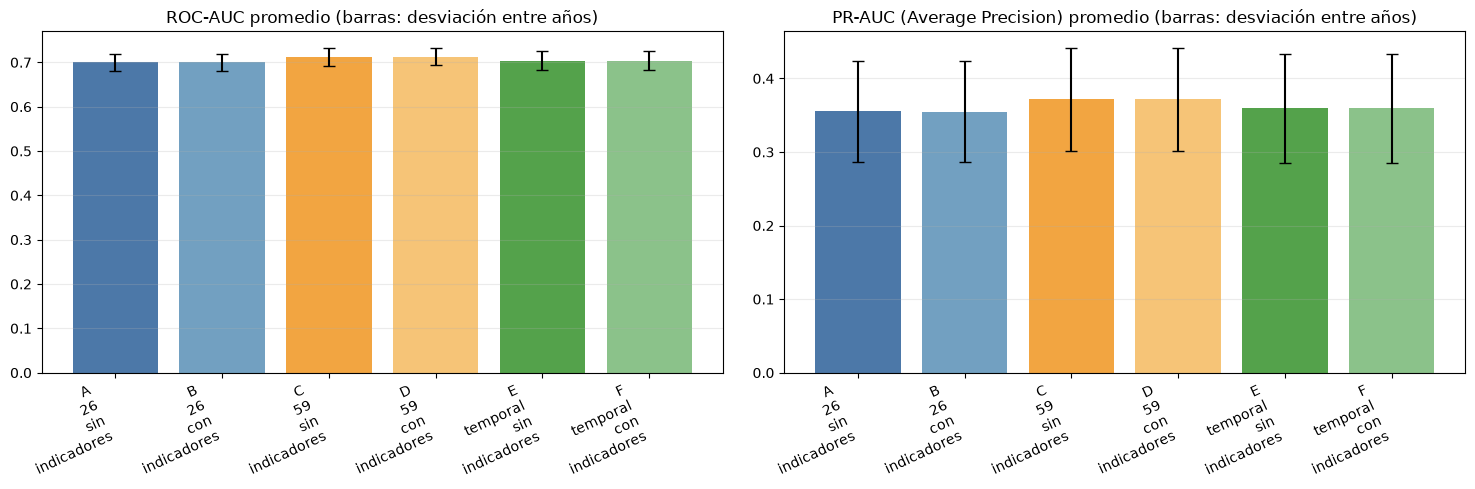

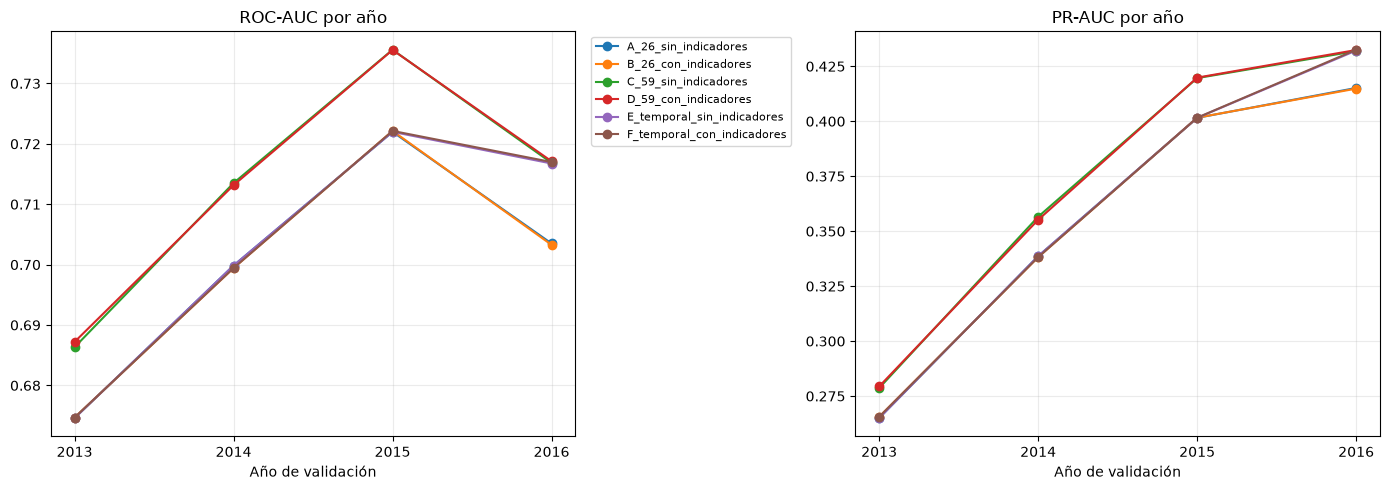

Resultados guardados en: C:\Users\josue\Proyecto-ML-Grupo8\outputs\comparacion_variables_temporal
59 exploratorias frente a 26 sin indicadores: Δ ROC-AUC=+0.01308.
Selección por corte frente a 26 sin indicadores: Δ ROC-AUC=+0.00331.
Indicadores en 26 variables: Δ ROC-AUC=-0.00010 (mejora en 2/4 cortes); Δ PR-AUC=-0.00003 (mejora en 2/4 cortes).
Indicadores en 59 variables (exploratorio): Δ ROC-AUC=+0.00019 (mejora en 2/4 cortes); Δ PR-AUC=+0.00000 (mejora en 3/4 cortes).
Indicadores en Selección por corte: Δ ROC-AUC=+0.00002 (mejora en 3/4 cortes); Δ PR-AUC=+0.00014 (mejora en 3/4 cortes).


In [7]:
resultados = pd.DataFrame(filas_resultados)
faltantes_detalle = pd.concat(filas_faltantes, ignore_index=True)

resumen = (resultados.groupby(["experimento", "tipo_seleccion"], as_index=False)
           .agg(ROC_AUC_promedio=("ROC_AUC", "mean"),
                ROC_AUC_desviacion=("ROC_AUC", "std"),
                PR_AUC_promedio=("PR_AUC", "mean"),
                PR_AUC_desviacion=("PR_AUC", "std"),
                variables_min=("variables_originales", "min"),
                variables_max=("variables_originales", "max"),
                indicadores_promedio=("indicadores_faltantes", "mean")))
resumen["ROC_AUC_desviacion"] = resumen["ROC_AUC_desviacion"].fillna(0)
resumen["PR_AUC_desviacion"] = resumen["PR_AUC_desviacion"].fillna(0)

pares = [
    ("26 variables", "A_26_sin_indicadores", "B_26_con_indicadores"),
    ("59 variables (exploratorio)", "C_59_sin_indicadores", "D_59_con_indicadores"),
    ("Selección por corte", "E_temporal_sin_indicadores", "F_temporal_con_indicadores"),
]
filas_pares=[]
for etiqueta, sin_ind, con_ind in pares:
    a = resultados.loc[resultados.experimento == sin_ind]
    b = resultados.loc[resultados.experimento == con_ind]
    merge = a[["anio_validacion", "ROC_AUC", "PR_AUC"]].merge(
        b[["anio_validacion", "ROC_AUC", "PR_AUC"]], on="anio_validacion", suffixes=("_sin", "_con"))
    filas_pares.append({
        "conjunto": etiqueta,
        "ROC_AUC_sin_indicadores": merge.ROC_AUC_sin.mean(),
        "ROC_AUC_con_indicadores": merge.ROC_AUC_con.mean(),
        "diferencia_ROC_AUC": (merge.ROC_AUC_con-merge.ROC_AUC_sin).mean(),
        "cortes_ROC_AUC_mejora": int((merge.ROC_AUC_con>merge.ROC_AUC_sin).sum()),
        "PR_AUC_sin_indicadores": merge.PR_AUC_sin.mean(),
        "PR_AUC_con_indicadores": merge.PR_AUC_con.mean(),
        "diferencia_PR_AUC": (merge.PR_AUC_con-merge.PR_AUC_sin).mean(),
        "cortes_PR_AUC_mejora": int((merge.PR_AUC_con>merge.PR_AUC_sin).sum()),
    })
comparacion_indicadores = pd.DataFrame(filas_pares)

display(resumen.round(5))
display(comparacion_indicadores.round(5))

display(resultados[["experimento", "anio_validacion", "variables_originales", "indicadores_faltantes", "ROC_AUC", "PR_AUC"]].sort_values(["experimento","anio_validacion"]).round(5))

# Porcentaje de faltantes por variable, conjunto y corte (solo entrenamiento).
display(faltantes_detalle.sort_values(
    ["experimento", "anio_validacion", "faltante_pct_entrenamiento"],
    ascending=[True, True, False]
).groupby(["experimento", "anio_validacion"], as_index=False).head(5).round(2))

# Gráficos de métricas promedio y estabilidad por año.
orden = ["A_26_sin_indicadores", "B_26_con_indicadores", "C_59_sin_indicadores",
         "D_59_con_indicadores", "E_temporal_sin_indicadores", "F_temporal_con_indicadores"]
resumen_plot = resumen.set_index("experimento").reindex(orden)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metrica, desviacion, titulo in [
    (axes[0], "ROC_AUC_promedio", "ROC_AUC_desviacion", "ROC-AUC promedio"),
    (axes[1], "PR_AUC_promedio", "PR_AUC_desviacion", "PR-AUC (Average Precision) promedio"),
]:
    ax.bar(range(len(orden)), resumen_plot[metrica], yerr=resumen_plot[desviacion], capsize=4,
           color=["#4C78A8", "#72A0C1", "#F2A541", "#F6C477", "#54A24B", "#8BC28A"])
    ax.set_xticks(range(len(orden)), [x.replace("_", "\n") for x in orden], rotation=25, ha="right")
    ax.set_title(titulo + " (barras: desviación entre años)")
    ax.grid(axis="y", alpha=.25)
fig.tight_layout()
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre in orden:
    subset = resultados[resultados.experimento == nombre].sort_values("anio_validacion")
    axes[0].plot(subset.anio_validacion, subset.ROC_AUC, marker="o", label=nombre)
    axes[1].plot(subset.anio_validacion, subset.PR_AUC, marker="o", label=nombre)
axes[0].set_title("ROC-AUC por año")
axes[1].set_title("PR-AUC por año")
for ax in axes:
    ax.set_xticks(ANIOS_VALIDACION)
    ax.set_xlabel("Año de validación")
    ax.grid(alpha=.25)
axes[0].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
display(fig)
plt.close(fig)

salida = RAIZ / "outputs" / "comparacion_variables_temporal"
salida.mkdir(parents=True, exist_ok=True)
resultados.to_csv(salida / "metricas_por_experimento_y_anio.csv", index=False)
resumen.to_csv(salida / "resumen_promedios_y_variabilidad.csv", index=False)
comparacion_indicadores.to_csv(salida / "comparacion_indicadores.csv", index=False)
faltantes_detalle.to_csv(salida / "faltantes_por_variable_y_corte.csv", index=False)
pd.DataFrame({"variable_26": pd.Series(variables_26), "variable_59": pd.Series(variables_59)}).to_csv(salida / "listas_26_y_59.csv", index=False)
print("Resultados guardados en:", salida)

# Lectura automática de hallazgos, sin afirmar significancia estadística.
idx = resumen.set_index("experimento")
delta_59 = idx.loc["C_59_sin_indicadores", "ROC_AUC_promedio"] - idx.loc["A_26_sin_indicadores", "ROC_AUC_promedio"]
delta_temporal = idx.loc["E_temporal_sin_indicadores", "ROC_AUC_promedio"] - idx.loc["A_26_sin_indicadores", "ROC_AUC_promedio"]
print(f"59 exploratorias frente a 26 sin indicadores: Δ ROC-AUC={delta_59:+.5f}.")
print(f"Selección por corte frente a 26 sin indicadores: Δ ROC-AUC={delta_temporal:+.5f}.")
for _, fila in comparacion_indicadores.iterrows():
    print(f"Indicadores en {fila['conjunto']}: Δ ROC-AUC={fila['diferencia_ROC_AUC']:+.5f} (mejora en {int(fila['cortes_ROC_AUC_mejora'])}/4 cortes); Δ PR-AUC={fila['diferencia_PR_AUC']:+.5f} (mejora en {int(fila['cortes_PR_AUC_mejora'])}/4 cortes).")


## 4. Conclusiones de esta ejecución

1. **Las 59 variables muestran mejores métricas que las 26:** ROC-AUC promedio 0.7131 frente a 0.7000 y PR-AUC 0.3717 frente a 0.3551. Sin embargo, esta comparación es exploratoria: las 59 se eligieron usando faltantes observados hasta 2016, que incluye años de validación.
2. **La selección hecha solo con cada entrenamiento también mejora moderadamente el promedio:** E obtiene ROC-AUC 0.7033 y PR-AUC 0.3593, frente a 0.7000 y 0.3551 con las 26 fijas. En los cortes 2013–2015 seleccionó las mismas 26; para validar 2016 seleccionó 57. La diferencia proviene, por tanto, del último corte.
3. **Los indicadores no aportaron una mejora clara:** con 26 variables, las diferencias medias fueron −0.00010 ROC-AUC y −0.00003 PR-AUC; con 59, +0.00019 y +0.000004; con selección por corte, +0.00002 y +0.00014. Son cambios mínimos y no se mantuvieron de forma consistente en los cuatro años.
4. **El beneficio de los indicadores no creció de forma práctica al ampliar las variables.** En los tres pares sus diferencias promedio son muy pequeñas, aunque en algunos cortes mejoró alguna métrica.
5. **Para una siguiente etapa, la evidencia favorece probar la selección por faltantes calculada solo con entrenamiento y mediana sin indicadores.** Esta opción evita usar el patrón de faltantes de los años de validación al elegir variables y obtiene un promedio algo superior al conjunto fijo de 26. La ventaja es modesta, así que conviene confirmarla al comparar los modelos; todavía no se cambia el modelo definitivo ni se evalúa la prueba final.

Las desviaciones estándar entre años son aproximadamente 0.0195 ROC-AUC / 0.0687 PR-AUC (A), 0.0213 / 0.0740 (E), 0.0203 / 0.0703 (C) y 0.0199 / 0.0702 (D). Son medidas de variación entre estos cuatro años, no pruebas de significancia estadística.

## 4. Cómo interpretar y límites

- A/B son la comparación fija con variables elegidas desde el primer entrenamiento; C/D son exploratorias porque la lista de 59 usó la cobertura observada hasta 2016.
- E/F no fuerzan un número de variables: se decide dentro de cada corte según los faltantes del entrenamiento. Por eso la cantidad de variables puede cambiar entre años.
- Un indicador permite que el modelo distinga un valor imputado de uno observado. Que la métrica cambie no demuestra por sí solo que el patrón de faltantes vaya a mantenerse en años futuros.
- Estas métricas sirven para comparar las decisiones de preprocesamiento en los cortes disponibles. No son una evaluación final y no se ajustan hiperparámetros, umbrales ni calibración.
- 2017 en adelante no participa en selección, imputación ni evaluación.

## Referencias

scikit-learn developers. (s. f.). *SimpleImputer*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html

scikit-learn developers. (s. f.). *ColumnTransformer*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html

scikit-learn developers. (s. f.). *HistGradientBoostingClassifier*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html